# Experiment 3: final model (tuned CNN-LSTM with hand-made features)

## Overview

**Purpose:** train the final model for live use: the CNN-LSTM with hand-made features from Experiment 2,
with a longer window, more overlap and more training data, then save everything the live program needs.

| Item | Setup |
|---|---|
| Data | same 7 recordings and preprocessing as Experiments 1–2 (`PREPRO.py`) |
| Window | 250 ms (15 samples at 60 Hz), new window every 2 samples, split 70 / 20 / 10 by time |
| Extra training data | each training window gets a noise copy (×2, noise = 5% of each channel's spread) |
| Model | CNN-LSTM with 32 hand-made features: 1 conv layer (64 filters, kernel 5, stride 2), LSTM memory 128 × 1 layer |
| Training | learning rate 0.0041, weight decay 0.0000085, dropout 0.025, early stopping, 3 seeds, GPU if available |
| Results | test accuracy, macro F1, size, speed, LDA baseline, per-recording and per-gesture scores |
| Saved for live use | checkpoint `CNN-LSTM_semg.pt`, TorchScript `CNN-LSTM_ts.pt`, `scaler.pkl` |

![Pipeline overview](Images/pipeline_overview.png)

### Steps
1. Load and clean the recordings
2. Cut windows, split by time, add noise copies, balance, normalise
3. Put the data into PyTorch
4. Build the model and check it
5. Train with 3 seeds (early stopping)
6. Test once
7. Save the model and export it for live use
8. Tune the settings with Optuna (optional re-run)

All settings are in the **Settings** cell.

### Tuning and final settings (CNN-LSTM)

| Setting | Experiment 2 search (150 ms) | Experiment 3 search (250 ms) | **Final model** |
|---|---|---|---|
| Conv layers, filters, kernel, stride | 1, 64, 5, 2 | 1, 32, 5, 2 | 1, **64**, 5, 2 |
| LSTM memory × layers | 128 × 1 | 128 × 1 | 128 × 1 |
| Hand-made features | on | on | on |
| Dropout | 0.043 | 0.025 | 0.025 |
| Learning rate | 0.0017 | 0.0041 | 0.0041 |
| Weight decay | 0.0025 | 0.0000085 | 0.0000085 |
| Window step, split | 4, 60 / 20 / 20 | 4, 60 / 20 / 20 | **2, 70 / 20 / 10** |
| Parameters | 103,271 | 85,511 | 103,271 |
| Validation / test accuracy | 86.7% / – | 92% / **86%** | 91.7% / **92.0%** |

### Results (final model, 250 ms window, 3 seeds, test set)

| Model | Accuracy | ± std | Macro F1 | Parameters | Model time (ms) | Total delay (ms) |
|---|---|---|---|---|---|---|
| **CNN-LSTM (with features)** | **92.0%** | 0.8% | **0.906** | 103,271 | 1.54 | 252 |
| LDA baseline | 70.6% | – | 0.702 | – | – | – |

- **Validation:** 91.7% ± 0.2% over 3 seeds.
- **Ablation:** signal strength alone (RMS) 70.4%, single sample 21.8%.
- **Per recording:** table 100%, rest 96.8%, extension 96.2%, flexion 95.9%, fist 93.7%, ulnar 88.0%,
  **radial 70.8%** (weakest; often predicted as another gesture).
- **Compared with Experiment 2:** 81.9% → 92.0% test accuracy (+10.1 points).

### Discussion
**Tuning result not used as-is.** The Experiment 3 search (250 ms, step 4, 60 / 20 / 20) found settings with
about 92% validation accuracy but only 86% on the test set. A 6-point gap means the search had fitted the
validation set: after 100 trials, the best trial is partly the luckiest one on that particular data. The
smaller width it chose (32) was therefore not trusted.

**Final choice.** The width was set back to 64, the value both the Experiment 2 search and the earlier
results supported, while the Experiment 3 training settings were kept (learning rate, weight decay, dropout).
The model shape (1 conv layer, LSTM 128 × 1, hand-made features) was the same in every search, so only the
size and training settings were in question. Furthermore, the window overlapping percentage was set to about ~78% through `step = 2`.

**Data changes.** The window step was reduced from 4 to 2 (overlap 73% → 87%), which roughly doubles the
number of windows, and the split was changed to 70 / 20 / 10, so the model trains on more of each recording.
With these changes, validation (91.7%) and test (92.0%) agree, which is the main sign that the result holds.

**Limits.**
- The decision to drop the tuned width was made after looking at a test score, so the test set
  is no longer completely unseen. The 92.0% may be slightly optimistic.
- The 86% and 92% come from different splits (60 / 20 / 20 vs 70 / 20 / 10)
- The test set is now 10% of each recording (1,828 windows), so each gesture has fewer test windows.
- Training accuracy reaches about 99%, so some overfitting remains.

### Conclusion
- **Accuracy target met:** 92.0% on unseen data is above the 90% target, with validation and test
  in agreement and a small spread between seeds.
- **Delay within budget:** window + model time is about 252 ms, under the 300 ms limit. Data
  acquisition time is not included, so the remaining margin is about 48 ms.
- **More data mattered more than tuning:** more overlap, noise copies and a larger training share lifted
  both the model and the untuned LDA baseline (61.9% → 70.6%).
- **Radial deviation** is still the weakest gesture and the main place to improve.
- **Next check:** test on a new recording session to confirm 92% without any test-based decisions.
- This model is the one saved and exported for live use.

In [70]:
# ---------------------------------------------------------------------------------------------
# Libraries
#
# What it does:
#     Load the libraries for data handling, plotting, scoring, the neural networks and the
#     project's own preprocessing file (PREPRO.py).
# ---------------------------------------------------------------------------------------------

import time                                                  # timing training and models
import importlib                                             # reload PREPRO.py after edits
from pathlib import Path                                     # file paths

import numpy as np                                           # arrays and maths
import pandas as pd                                          # result tables
import matplotlib.pyplot as plt                              # charts
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay   # scores and confusion matrices
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis                                 # LDA baseline

import torch                                                 # neural networks
import torch.nn as nn                                        # layers (Conv1d, LSTM, Linear, ...)
import torch.nn.functional as F                              # functions such as padding

import PREPRO as pp                                          # loading, cleaning, windows, split
importlib.reload(pp)                                         # picks up any edits to PREPRO.py without restarting the kernel
from IPython.display import display                          # show formatted tables from inside a cell

## Settings

| Group | Setting | What it does |
|---|---|---|
| Data | `DATA_FOLDER`, `CHANNELS`, `GESTURES` | where the recordings are, which columns are signal, which gestures to classify |
| Signal | `SAMPLE_RATE` | readings per second per channel. Step 1 prints the rate measured from `Time`: make them match |
| Signal | `PREP` | everything passed to `pp.preprocess` (outliers, notch, band-pass, causal or zero-phase, per file) |
| Windows | `WINDOW_MS`, `STEP` | window length (the system's delay) and the gap between window starts |
| Split | `VAL_FRAC`, `TEST_FRAC` | the last part of every recording held out for validation and test |
| Split | `MAX_GAP_MS` | skip windows that jump over missing rows (e.g. removed outliers). `None` = off |
| Balance | `BALANCE_TRAIN`, `DATA_SEED` | cap training gestures at the median count; fixed seed so the data never changes between runs |
| Training | `BATCH_SIZE`, `EPOCHS`, `LEARNING_RATE`, `SEEDS` | training settings; every model is trained once per seed |

In [ ]:
# ---------------------------------------------------------------------------------------------
# Settings
#
# What it does:
#     Every data, signal, window, split, training and hardware setting in one place. Changing a
#     value here and re-running from the top changes the whole experiment.
# ---------------------------------------------------------------------------------------------

# ---------- data ----------
DATA_FOLDER = "Data"                                         # folder with one sub-folder per recording
CHANNELS = [f"V{i+1}" for i in range(8)]                     # signal columns V1..V8
GESTURES = {"fist": 1, "flexion": 2, "extension": 3, "radial": 4, "ulnar": 5, "rest": 6, "table": 7}   # gesture -> number

# ---------- signal (passed to pp.preprocess) ----------
SAMPLE_RATE = 60                                             # readings per second per channel (Hz)
PREP = dict(
    sample_rate=SAMPLE_RATE,                                 # used to design the filters
    resample=False,                                          # True: even time grid from Time; False: rows as recorded
    outlier_z=3.0,                                           # drop rows beyond 3 std devs; None = keep all
    zero_centre=True,                                        # subtract each channel's mean
    notch_hz=None,                                           # mains-hum notch filter; None = off
    low_hz=1,                                                # band-pass lower edge (Hz)
    high_hz=8,                                               # band-pass upper edge (Hz)
    filter_order=4,                                          # filter steepness
    causal=True,                                             # filters only look at the past, as in live use
    per_file=True,                                           # outliers and filters per recording
)

# ---------- windows and split (passed to pp.make_datasets) ----------
WINDOW_MS = 250                                              # window length = delay (ms)
WINDOW_SIZE = SAMPLE_RATE * WINDOW_MS // 1000                # samples per window (15 at 60 Hz)
STEP = 2                                                     # samples between window starts (87% overlap)
SPLIT_BY = "chrono"                                          # each recording: train, then validation, then test
VAL_FRAC, TEST_FRAC = 0.1, 0.2                              # 70 / 10 / 20 split
MAX_GAP_MS = None                                            # skip windows over a real gap; None = off
BALANCE_TRAIN = True                                         # cap training gestures at the median count
DATA_SEED = 0                                                # fixed seed: the data never changes between runs

# ---------- training ----------
BATCH_SIZE = 64                                              # windows per weight update
EPOCHS = 60                                        # upper limit; training stops early
PATIENCE = 8                                       # stop after this many epochs without a better val accuracy
LEARNING_RATE = 0.0040619880891515974                        # tuned step size of each weight update
SEEDS = [0, 1, 2]                                  # model seeds: starting weights, batch order, dropout
WEIGHT_DECAY = 8.504021823437331e-06                               # L2 regularisation; 0 disables
# ---------- hardware ----------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # GPU if available
print("training on", DEVICE, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")   # which device is used

print(f"window: {WINDOW_MS} ms = {WINDOW_SIZE} samples at {SAMPLE_RATE} Hz, step {STEP}")   # quick check

training on cpu 
window: 250 ms = 15 samples at 60 Hz, step 2


## Step 1: load and clean the recordings

`pp.preprocess` reads every file in `DATA_FOLDER`, removes outlier rows, zero-centres each channel and applies
the notch and band-pass filters set in `PREP`. It returns one table with columns
`file, file_idx, Time, V1..V8, Gesture`, so the time stamps are kept for later use.

Check the printed **measured rate**: if it differs from `SAMPLE_RATE`, the filter edges and window length
in milliseconds are not what the settings say.

In [72]:
# ---------------------------------------------------------------------------------------------
# Step 1: load and clean the recordings
#
# What it does:
#     Read every recording, remove outliers, zero-centre and filter each channel (settings in PREP).
#     Returns one table with columns file, file_idx, Time, V1..V8, Gesture.
# ---------------------------------------------------------------------------------------------

PREP_RAW_TIME = {**PREP, "resample": False}                  # copy of PREP with rows kept as recorded (no time grid)
data = pp.preprocess(DATA_FOLDER, channels=CHANNELS, **PREP_RAW_TIME)   # load + clean; prints a timing report

loaded 7 files, 41709 rows
recorded timing per file (gaps between rows, ms):
        gesture  rows  length (s)  rate (Hz)  short <=10 ms (%)  pauses  longest pause (s)  duplicates
file                                                                                                  
01         fist  8678       269.5       53.4               41.7      89                6.0           0
02      flexion  5098       201.5       52.5               36.7      79               10.3           1
03    extension  5485       225.2       52.7               36.4      73               44.1           0
04       radial  4334       163.3       52.9               37.3      68               31.4           0
05        ulnar  3816       138.5       54.5               38.8      56                8.1           0
06         rest  6328       119.1       53.2               37.8       2                0.1           1
07        table  7970       155.6       51.2               34.8       0                0.1         

## Step 2: windows, split, balance and normalise

`pp.make_datasets` cuts every recording into windows of `WINDOW_SIZE` samples (a new window every `STEP`
samples), keeping only windows with a single gesture label. Each recording is split along time: the first
70% for training, the next 20% for validation and the last 10% for testing. Windows that cross a cut are
dropped, and a check confirms that no raw sample is shared between splits.

Every training window also gets a noise copy (×2; noise = 5% of each channel's spread), training gestures
are capped at the median count, and every channel is normalised with statistics from the training windows only.

In [73]:
# ---------------------------------------------------------------------------------------------
# Step 2: windows, split, balance and normalise
#
# What it does:
#     Cut every recording into windows, split each recording by time into train / validation /
#     test, cap training gestures at the median count and normalise with training statistics.
#
# Steps:
#     1. Make the datasets with pp.make_datasets.
#     2. Unpack the windows, labels and details used by later steps.
# ---------------------------------------------------------------------------------------------

d = pp.make_datasets(data, WINDOW_SIZE, STEP, channels=CHANNELS, gestures=GESTURES,        # 1. windows of WINDOW_SIZE, one every STEP
                     val_frac=VAL_FRAC, test_frac=TEST_FRAC, max_gap_ms=MAX_GAP_MS,        #    split fractions, gap check
                     balance_train=BALANCE_TRAIN, data_seed=DATA_SEED)                     #    capping, fixed data seed

X_train, y_train = d["X_train"], d["y_train"]               # 2. training windows [n, time, 8] and labels
X_val,   y_val   = d["X_val"],   d["y_val"]                 #    validation (early stopping, model choice)
X_test,  y_test  = d["X_test"],  d["y_test"]                #    test (used once, at the end)
test_file        = d["test_file"]                           #    recording each test window came from
GESTURE_NAMES    = d["gesture_names"]                       #    class number -> gesture name
N_CLASSES        = d["n_classes"]                           #    number of gestures (7)
channel_mean, channel_std = d["channel_mean"], d["channel_std"]   # normalisation, needed again for live use

                windows  train  val  test  dropped
file gesture                                      
01   fist          3856   2697  766   379       14
02   flexion       2244   1569  443   218       14
03   extension     2454   1716  485   239       14
04   radial        1916   1339  378   185       14
05   ulnar         1715   1198  337   166       14
06   rest          2904   2030  575   285       14
07   table         3620   2532  718   356       14 

windows: 15 samples, step 2; train 21940, val 3702, test 1828; samples shared between splits: 0
augmented training set: 10970 -> 21940 windows (x2, Gaussian noise std 0.05 of channel std)
capped each training gesture at 1716 windows:
  fist          2697 ->  1716
  flexion       1569 ->  1569
  extension     1716 ->  1716
  radial        1339 ->  1339
  ulnar         1198 ->  1198
  rest          2030 ->  1716
  table         2532 ->  1716


## Step 3: put the data into PyTorch

In [74]:
# ---------------------------------------------------------------------------------------------
# Step 3: put the data into PyTorch
#
# What it does:
#     Wrap the windows and labels as PyTorch datasets and loaders (batches), move one batch to the
#     training device, and print its shape as a check.
# ---------------------------------------------------------------------------------------------

train_data = torch.utils.data.TensorDataset(torch.tensor(X_train), torch.tensor(y_train))   # windows + labels
val_data   = torch.utils.data.TensorDataset(torch.tensor(X_val),   torch.tensor(y_val))
test_data  = torch.utils.data.TensorDataset(torch.tensor(X_test),  torch.tensor(y_test))

train_loader = torch.utils.data.DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)   # shuffled batches for training
val_loader   = torch.utils.data.DataLoader(val_data,   batch_size=BATCH_SIZE)                 # fixed order for scoring
test_loader  = torch.utils.data.DataLoader(test_data,  batch_size=BATCH_SIZE)

batch_x, batch_y = next(iter(train_loader))                  # one batch, used by the shape checks
batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)      # same device as the models
print("one batch of windows:", tuple(batch_x.shape), "(batch, time steps, channels)")
print("one batch of labels: ", tuple(batch_y.shape),
      f"values {int(batch_y.min())}..{int(batch_y.max())}")  # labels 0 .. N_CLASSES-1

one batch of windows: (64, 15, 8) (batch, time steps, channels)
one batch of labels:  (64,) values 0..6


## Step 4: the model

In [75]:
def pad_left(x, kernel_size, dilation=1, stride=1):
    """
    What it does:
        Add zeros on the left (the past) of the time axis, so a convolution keeps the length and
        never uses a future sample. Return the padded tensor.

    Steps:
        1. Causal padding: (kernel_size - 1) * dilation zeros.
        2. With stride > 1: extra zeros so the last filter position ends on the newest sample.
        3. Pad the last dimension (time) on the left only.
    """
    pad = (kernel_size - 1) * dilation + (-(x.shape[-1] - 1)) % stride   # 1-2. number of zeros
    return F.pad(x, (pad, 0))                                             # 3. (left, right) on the time axis

### 4a. LSTM

Same model as Experiment 2. Only change: dropout between LSTM layers is switched off when there is only
one layer (`dropout if layers > 1 else 0.0`), which removes the PyTorch warning. Not run in this experiment
(commented out in `MODEL_CLASSES`).

In [76]:
class LSTMModel(nn.Module):
    """
    What it does:
        Classify one window with an LSTM (memory only, no convolution).

    Steps:
        1. LSTM reads the 8 channel values at every time step and updates its memory.
        2. Keep the output of the last time step (summary of the whole window).
        3. Dropout, then a linear layer gives one score per gesture.

    Settings: hidden = memory size, layers = stacked LSTMs, dropout = share of values switched off
    in training.
    """
    def __init__(self, n_channels=8, n_classes=7, hidden=64, layers=2, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_channels, hidden_size=hidden, num_layers=layers,
                            batch_first=True, dropout=dropout if layers > 1 else 0.0)   # dropout only between stacked LSTMs
        self.dropout = nn.Dropout(dropout)                   # before the final layer
        self.fc = nn.Linear(hidden, n_classes)               # memory -> gesture scores

    def all_steps(self, x):                 # x: [batch, time, 8]
        """LSTM output at every time step: [batch, time, hidden]."""
        out, _ = self.lstm(x)               # final memory states not needed
        return out                          # [batch, time, hidden]

    def forward(self, x):
        """Gesture scores for each window: last time step -> dropout -> linear. [batch, n_classes]."""
        last_step = self.all_steps(x)[:, -1, :]              # newest time step only
        return self.fc(self.dropout(last_step))

### 4b. CNN

Same model as Experiment 2 (2 plain causal conv layers, filters `width` then 2 × `width`). Not run in this
experiment (commented out in `MODEL_CLASSES`).

In [77]:
class CNNModel(nn.Module):
    """
    What it does:
        Classify one window with stacked causal 1D convolutions (patterns only, no memory).

    Steps:
        1. Flip the window to channels-first for Conv1d.
        2. Each layer: pad on the left, convolve, batch norm, ReLU.
        3. Keep the output at the newest time step.
        4. Dropout, then a linear layer gives one score per gesture.

    Settings: width = filters in the first layer (later layers 2 x width), kernel_size = samples per
    filter, n_layers = number of conv layers. Reach = 1 + (kernel_size - 1) x n_layers samples.
    """
    def __init__(self, n_channels=8, n_classes=7, width=32, kernel_size=5, n_layers=2, dropout=0.3):
        super().__init__()
        self.kernel_size = kernel_size                       # same filter size in every layer
        widths = [width] + [2 * width] * (n_layers - 1)      # e.g. 32, 64
        self.convs, self.bns = nn.ModuleList(), nn.ModuleList()   # lists PyTorch can train
        n_in = n_channels                                    # first layer reads the 8 electrodes


        for w in widths:                                     # one conv + batch norm per layer
            self.convs.append(nn.Conv1d(n_in, w, kernel_size))   # n_in inputs -> w filters
            self.bns.append(nn.BatchNorm1d(w))               # keeps each filter's output on a steady scale
            n_in = w                                         # next layer reads this layer's output
        self.dropout = nn.Dropout(dropout)                   # switches off random values in training
        self.fc = nn.Linear(n_in, n_classes)                 # last layer's filters -> gesture scores

    def all_steps(self, x):                 # x: [batch, time, 8]
        """Conv output at every time step: [batch, time, last layer's filters]."""
        x = x.transpose(1, 2)               # -> [batch, 8, time]
        for conv, bn in zip(self.convs, self.bns):
            x = torch.relu(bn(conv(pad_left(x, self.kernel_size))))   # pad, convolve, normalise, keep positives
        return x.transpose(1, 2)            # -> [batch, time, channels]

    def forward(self, x):
        """Gesture scores for each window: last time step -> dropout -> linear. [batch, n_classes]."""
        last_step = self.all_steps(x)[:, -1, :]              # newest time step only
        return self.fc(self.dropout(last_step))

### 4c. CNN-LSTM (with hand-made features)

The CNN-LSTM-WF from Experiment 2 becomes the single final model. Changes:

| | Experiment 2 (CNN-LSTM-WF) | Experiment 3 |
|---|---|---|
| Window | 9 samples | 15 samples |
| Conv layers | fixed: 2 layers, 32 and 32 filters | `cnn_layers` (1–4), filters `width` then 2 × `width`; tuned: **1 layer** |
| Stride | on layer 2 | on the last layer only (here the only layer): 15 → 8 time steps |
| LSTM | memory 64, 1 layer (`layers`) | memory **128**, `lstm_layers` = 1 |
| Hand-made features | separate model name (`-WF`) | always on (`use_features=True`) |
| Dropout | 0.3 | 0.025 (tuned) |
| Parameters | 32,423 | 103,271 |
| Device | CPU | GPU when available (`DEVICE`) |

**Why:** the Optuna search (validation only) preferred one conv layer with a larger LSTM memory and the
hand-made features on. With the stride, the LSTM reads 8 steps that together cover the whole 15-sample window,
so a deeper CNN is not needed to see the full window. The larger memory explains most of the extra parameters.

In [78]:
def hand_made_features_torch(x):
    """
    What it does:
        Compute 4 classic sEMG features per channel over the whole window (torch version, used
        inside the model so live windows get the same features).

    Steps:
        1. RMS: square, average over time, square root (signal strength).
        2. MAV: average absolute value (average size).
        3. WL: sum of absolute changes between neighbouring samples (how much it wiggles).
        4. ZC: number of sign changes (zero crossings).
        5. Join the four [batch, 8] blocks into [batch, 32].
    """
    rms = torch.sqrt(torch.mean(x ** 2, dim=1))                      # 1. signal strength        [batch, 8]
    mav = torch.mean(torch.abs(x), dim=1)                            # 2. average size           [batch, 8]
    wl  = torch.sum(torch.abs(torch.diff(x, dim=1)), dim=1)          # 3. how much it wiggles    [batch, 8]
    zc  = torch.sum(torch.diff(torch.sign(x), dim=1) != 0, dim=1).float()   # 4. zero crossings  [batch, 8]
    return torch.cat([rms, mav, wl, zc], dim=1)                      # 5. side by side           [batch, 32]

In [79]:
class CNNFrontEnd(nn.Module):
    """
    What it does:
        Turn the raw window into a shorter sequence of pattern features for the LSTM.

    Steps:
        1. Flip the window to channels-first for Conv1d.
        2. Each conv layer: pad on the left, convolve, batch norm, ReLU.
           Only the last layer uses the stride (2 = half as many time steps).
        3. Flip back to time-first for the LSTM.

    Settings: width = filters in the first layer (later layers 2 x width), kernel_size = samples per
    filter, stride = step of the last layer, n_layers = number of conv layers.
    """
    def __init__(self, n_channels=8, width=32, kernel_size=5, stride=2, n_layers=2):
        super().__init__()
        self.kernel_size = kernel_size                           # same filter size in every layer
        widths = [width] + [2 * width] * (n_layers - 1)          # e.g. 32, 64
        self.strides = [1] * (n_layers - 1) + [stride]           # e.g. 1, 2  (stride on last layer only)

        self.convs, self.bns = nn.ModuleList(), nn.ModuleList()   # lists PyTorch can train
        n_in = n_channels                                        # first layer reads the 8 electrodes
        for w, s in zip(widths, self.strides):                   # one conv + batch norm per layer
            self.convs.append(nn.Conv1d(n_in, w, kernel_size, stride=s))   # n_in inputs -> w filters
            self.bns.append(nn.BatchNorm1d(w))                   # keeps each filter's output on a steady scale
            n_in = w                                             # next layer reads this layer's output
        self.out_channels = n_in                                 # last layer's filters -> LSTM input size

    def forward(self, x):                                        # x: [batch, time, 8]
        """Pattern features: [batch, time / stride, out_channels]."""
        x = x.transpose(1, 2)                                    # -> [batch, 8, time]
        for conv, bn, s in zip(self.convs, self.bns, self.strides):
            x = torch.relu(bn(conv(pad_left(x, self.kernel_size, stride=s))))   # pad, convolve, normalise, keep positives
        return x.transpose(1, 2)                                 # -> [batch, time / stride, out_channels]


class CNNLSTMModel(nn.Module):
    """
    What it does:
        Classify one window with the CNN front-end (patterns) followed by an LSTM (order over time),
        optionally joined with 32 hand-made features before the final layer.

    Steps:
        1. CNNFrontEnd turns the window into a sequence of pattern features.
        2. LSTM reads that sequence step by step.
        3. Keep the LSTM output at the last time step.
        4. If use_features: compute RMS, MAV, WL, ZC from the raw window, rescale with batch norm,
           and join them with the LSTM output (hidden + 32 numbers).
        5. Dropout, then a linear layer gives one score per gesture.

    Settings: cnn_layers = conv layers, lstm_layers = stacked LSTMs, hidden = LSTM memory size.
    """
    def __init__(self, n_channels=8, n_classes=7, width=32, kernel_size=5, stride=2,
                 hidden=64, cnn_layers=2, lstm_layers=1, dropout=0.3, use_features=False):
        super().__init__()
        self.cnn = CNNFrontEnd(n_channels, width, kernel_size, stride, cnn_layers)   # pattern part
        self.lstm = nn.LSTM(input_size=self.cnn.out_channels, hidden_size=hidden, num_layers=lstm_layers,
                            batch_first=True, dropout=dropout if lstm_layers > 1 else 0.0)   # dropout only between stacked LSTMs
        self.dropout = nn.Dropout(dropout)                   # before the final layer

        # Optional hand-made features: computed from the raw window, they skip the CNN and LSTM
        # and are joined with the LSTM's last output just before the final linear layer.
        self.use_features = use_features
        n_features = 4 * n_channels if use_features else 0   # 32 extra numbers, or none
        if use_features:
            self.feature_bn = nn.BatchNorm1d(n_features)     # puts the 32 features on one scale
        self.fc = nn.Linear(hidden + n_features, n_classes)  # LSTM output (+ features) -> gesture scores

    def all_steps(self, x):
        """LSTM output at every (strided) time step: [batch, time / stride, hidden]."""
        out, _ = self.lstm(self.cnn(x))     # CNN patterns, then LSTM
        return out

    def forward(self, x):
        """Gesture scores for each window: [batch, n_classes]."""
        last_step = self.all_steps(x)[:, -1, :]              # newest time step only
        if self.use_features:
            features = self.feature_bn(hand_made_features_torch(x))   # 32 features from the raw window
            last_step = torch.cat([last_step, features], dim=1)     # join: hidden + 32
        return self.fc(self.dropout(last_step))

### 4d. Build and check the model


`MODEL_CLASSES` lists the models in a fixed order. Every later step loops over it, so to leave a model out, delete its line here.

The seed is reset before building each model, so every model starts from the same kind of random weights. That keeps the comparison fair.

In [ ]:
# ---------------------------------------------------------------------------------------------
# Model, settings and building
#
# What it does:
#     List the models to run, keep every model setting in PARAMS, and build each model once to
#     check its shapes and size.
#
# Steps:
#     1. MODEL_CLASSES: models every later step loops over (commented out = skipped).
#     2. PARAMS: tuned model settings, plus the training settings (learning rate, weight decay, batch size).
#     3. build_model: create one untrained model with a fixed seed, on the training device.
#     4. Build each model and print input -> output shapes and parameter count.
# ---------------------------------------------------------------------------------------------

MODEL_CLASSES = {#"LSTM": LSTMModel,                        # 1. commented out = not run
                #"CNN": CNNModel,
                "CNN-LSTM": CNNLSTMModel,
                }

# every setting of every model in one place; tuning (Step 8) replaces these
PARAMS = {                                                   # 2. model settings
    #"LSTM":     dict(hidden=64, layers=1, dropout=0.3),
    #"CNN":      dict(width=32, kernel_size=5, n_layers=2, dropout=0.3),
    "CNN-LSTM": dict(width=64, kernel_size=5, stride=2, hidden=128, cnn_layers = 1, lstm_layers=1, dropout=0.025240962295266033, use_features=True),

}
for p in PARAMS.values():                                   # training settings, also tunable
    p.update(lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY, batch_size=BATCH_SIZE)

TRAIN_KEYS = ("lr", "weight_decay", "batch_size")           # these go to the optimiser, not the model


def build_model(name, seed=0, params=None):
    """
    What it does:
        Create one untrained model with a fixed seed, on the training device.

    Steps:
        1. Use the given params, otherwise PARAMS[name].
        2. Set the seed, so the same seed always gives the same starting weights.
        3. Drop the training-only settings (lr, weight_decay, batch_size).
        4. Build the model class from MODEL_CLASSES with N_CLASSES outputs and move it to DEVICE.
    """
    params = params or PARAMS[name]                         # 1. settings
    torch.manual_seed(seed)                                 # 2. same seed -> same starting weights
    model_args = {k: v for k, v in params.items() if k not in TRAIN_KEYS}   # 3. model settings only
    return MODEL_CLASSES[name](n_classes=N_CLASSES, **model_args).to(DEVICE)   # 4. model on GPU/CPU


for name in MODEL_CLASSES:                                  # 4. shape and size check
    model = build_model(name)
    model.eval()                                            # dropout off, batch norm fixed
    with torch.no_grad():                                   # no training here
        steps = model.all_steps(batch_x)                    # output at every time step
        scores = model(batch_x)                             # gesture scores
    n_params = sum(p.numel() for p in model.parameters())   # model size
    print(f"{name:9s} input {tuple(batch_x.shape)} -> every step {tuple(steps.shape)} "
          f"-> scores {tuple(scores.shape)}   parameters: {n_params:,}")

CNN-LSTM  input (64, 15, 8) -> every step (64, 8, 128) -> scores (64, 7)   parameters: 103,271


In [81]:
# ---------------------------------------------------------------------------------------------
# Shape check: one batch through the CNN-LSTM
#
# What it does:
#     Run one batch through the CNN-LSTM layer by layer and print the shape after each step.
#     No training happens.
#
# Steps:
#     1. Build the CNN-LSTM and switch it to evaluation mode.
#     2. Flip the window to channels-first.
#     3. Each conv layer: pad on the left, convolve (the last layer uses the stride).
#     4. Flip back to time-first and run the LSTM over every step.
#     5. Keep the last time step.
#     6. If hand-made features are on: compute them and join them with the LSTM output.
#     7. Turn the result into one score per gesture.
# ---------------------------------------------------------------------------------------------

model = build_model("CNN-LSTM")                              # 1. untrained model, fixed seed
model.eval()                                                 #    dropout off, batch norm fixed
cnn = model.cnn                                              #    the CNN front-end inside the model
k = cnn.kernel_size                                          #    filter size

with torch.no_grad():                                        #    shapes only
    x = batch_x;                       print("input:                ", tuple(x.shape))   # [batch, time, 8]
    h = x.transpose(1, 2);             print("flip for Conv1d:      ", tuple(h.shape))   # 2. [batch, 8, time]
    for i, (conv, bn, s) in enumerate(zip(cnn.convs, cnn.bns, cnn.strides), start=1):   # 3. one conv layer at a time
        h = pad_left(h, k, stride=s);  print("pad on the left:      ", tuple(h.shape))   #    zeros added in the past
        h = torch.relu(bn(conv(h)));   print(f"conv{i} (stride {s}):     ", tuple(h.shape))   #    [batch, filters, time / stride]
    h = h.transpose(1, 2);             print("flip for LSTM:        ", tuple(h.shape))   # 4. time first
    h, _ = model.lstm(h);              print("LSTM, every step:     ", tuple(h.shape))   #    [batch, steps, hidden]
    h = h[:, -1, :];                   print("last step only:       ", tuple(h.shape))   # 5. [batch, hidden]
    if model.use_features:                                                              # 6.
        f = model.feature_bn(hand_made_features_torch(x));   print("hand-made features:   ", tuple(f.shape))   # [batch, 32]
        h = torch.cat([h, f], dim=1);                         print("joined:               ", tuple(h.shape))   # [batch, hidden + 32]
    h = model.fc(h);                   print("gesture scores:       ", tuple(h.shape))   # 7. [batch, 7]

input:                 (64, 15, 8)
flip for Conv1d:       (64, 8, 15)
pad on the left:       (64, 8, 19)
conv1 (stride 2):      (64, 64, 8)
flip for LSTM:         (64, 8, 64)
LSTM, every step:      (64, 8, 128)
last step only:        (64, 128)
hand-made features:    (64, 32)
joined:                (64, 160)
gesture scores:        (64, 7)


## Step 5: training 

In [82]:
loss_fn = nn.CrossEntropyLoss()        # Loss function: compares gesture scores with true labels.


def train_one_epoch(model, loader, optimizer):
    """
    What it does:
        Train the model for one pass over all training windows. Return average loss and accuracy.

    Steps:
        1. Switch the model to training mode (dropout on, batch norm updates its statistics).
        2. Take one batch of windows and labels.
        3. Compute gesture scores (forward pass).
        4. Compute the loss between scores and labels.
        5. Clear old gradients.
        6. Compute new gradients (backward pass).
        7. Update the weights.
        8. Add the batch loss and correct predictions to running totals.
        9. Repeat steps 2-8 for every batch.
        10. Return average loss and accuracy.
    """
    model.train()                                              # 1. Training mode.
    total_loss, correct, count = 0.0, 0, 0
    for windows, labels in loader:                             # 2. One batch.
        windows, labels = windows.to(DEVICE), labels.to(DEVICE)    #    Move batch to the model's device.
        scores = model(windows)                                # 3. Forward pass.
        loss = loss_fn(scores, labels)                         # 4. Loss.
        optimizer.zero_grad()                                  # 5. Clear gradients.
        loss.backward()                                        # 6. Backward pass.
        optimizer.step()                                       # 7. Update weights.
        total_loss += loss.item() * len(labels)                # 8. Sum loss over windows.
        correct += (scores.argmax(dim=1) == labels).sum().item()   # 8. Count correct predictions.
        count += len(labels)
    return total_loss / count, correct / count                 # 10. Average loss, accuracy.


def evaluate(model, loader):
    """
    What it does:
        Score the model on a dataset without changing any weights. Return average loss and accuracy.

    Steps:
        1. Switch the model to evaluation mode (dropout off, batch norm uses stored statistics).
        2. Turn off gradient tracking.
        3. Take one batch of windows and labels.
        4. Compute gesture scores.
        5. Add the batch loss and correct predictions to running totals.
        6. Repeat steps 3-5 for every batch.
        7. Return average loss and accuracy.
    """
    model.eval()                                               # 1. Evaluation mode.
    total_loss, correct, count = 0.0, 0, 0
    with torch.no_grad():                                      # 2. No gradients.
        for windows, labels in loader:                         # 3. One batch.
            windows, labels = windows.to(DEVICE), labels.to(DEVICE)   # Move batch to the model's device.
            scores = model(windows)                            # 4. Forward pass only.
            total_loss += loss_fn(scores, labels).item() * len(labels)   # 5. Sum loss.
            correct += (scores.argmax(dim=1) == labels).sum().item()     # 5. Count correct.
            count += len(labels)
    return total_loss / count, correct / count                 # 7. Average loss, accuracy.


def train_model(name, seed=0, params=None, trial=None):
    """
    What it does:
        Train one model from scratch with early stopping. Keep the weights from the epoch with the
        best validation accuracy. Return the training history.
        Normal mode (trial=None): print progress, save best weights to file.
        Tuning mode (trial given): report to Optuna, allow early cut-off, save nothing.

    Steps:
        1. Load settings: given params, otherwise PARAMS[name].
        2. Build the model with the given seed.
        3. Build the training loader (batch size from settings, shuffle order fixed by seed).
        4. Build the optimiser (AdamW: learning rate and weight decay from settings).
        5. For each epoch:
           5a. Train for one epoch.
           5b. Score on the validation set.
           5c. Record losses and accuracies.
           5d. If validation accuracy is a new best: store a copy of the weights, reset wait counter.
               Otherwise: increase wait counter.
           5e. Tuning mode: report validation accuracy; stop the trial if Optuna marks it as poor.
               Normal mode: print epoch results.
           5f. Stop if wait counter reaches PATIENCE.
        6. Normal mode: save best weights to "best_{name}_seed{seed}.pt".
        7. Return the history.
    """
    params = params or PARAMS[name]                            # 1. Settings.
    model = build_model(name, seed, params)                    # 2. Model, seeded weights.
    loader = torch.utils.data.DataLoader(train_data, batch_size=params["batch_size"], shuffle=True,
                                         generator=torch.Generator().manual_seed(seed))   # 3. Seeded shuffle.
    optimizer = torch.optim.AdamW(model.parameters(), lr=params["lr"],
                                  weight_decay=params["weight_decay"])                  # 4. Optimiser.
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc, best_state, wait = 0.0, None, 0

    for epoch in range(1, EPOCHS + 1):                         # 5. Epoch loop (EPOCHS = upper limit).
        train_loss, train_acc = train_one_epoch(model, loader, optimizer)    # 5a. Train.
        val_loss, val_acc = evaluate(model, val_loader)                      # 5b. Validate.
        history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)   # 5c. Record.
        history["train_acc"].append(train_acc);   history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:                             # 5d. New best epoch.
            best_val_acc, wait = val_acc, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}  # Copy weights in memory.
        else:
            wait += 1                                          # 5d. No improvement.

        if trial is not None:                                  # 5e. Tuning mode.
            trial.report(val_acc, epoch)                       # Send score to Optuna.
            if trial.should_prune():                           # Poor compared with earlier trials.
                raise optuna.TrialPruned()                     # End this trial now.
        else:                                                  # 5e. Normal mode.
            print(f"  epoch {epoch:2d}  train acc {train_acc:.1%}  val acc {val_acc:.1%}"
                  f"{'  <- best' if wait == 0 else ''}")
        if wait >= PATIENCE:                                   # 5f. Early stop.
            break

    if trial is None:                                          # 6. Normal mode only.
        torch.save(best_state, f"best_{name}_seed{seed}.pt")   # One file write per model and seed.
    return history                                             # 7. History.

In [83]:
# ---------------------------------------------------------------------------------------------
# Train every model with every seed
#
# What it does:
#     Train each model once per seed, record the training time, and pick the seed with the best
#     validation accuracy for the plots and the saved model.
#
# Steps:
#     1. For each model and each seed: train from scratch and time the run.
#     2. Pick the seed whose best validation accuracy is highest.
#     3. Keep that seed's training history for the plots.
#     4. Store the average training time per run.
#     5. Print the mean ± std of the best validation accuracy over all seeds.
# ---------------------------------------------------------------------------------------------

histories, training_seconds, chosen_seed = {}, {}, {}    # results per model name

for name in MODEL_CLASSES:
    run_histories, times = {}, []                        # this model: history and time per seed
    for seed in SEEDS:                                   # 1. one full training run per seed
        print(f"Training {name}, seed {seed}")
        start_time = time.time()
        run_histories[seed] = train_model(name, seed)    #    trains, saves best_{name}_seed{seed}.pt
        times.append(time.time() - start_time)           #    seconds for this run

    # the seed with the best validation accuracy is used for the plots and saved model
    chosen_seed[name] = max(SEEDS, key=lambda s: max(run_histories[s]["val_acc"]))   # 2. best seed (validation only)
    histories[name] = run_histories[chosen_seed[name]]                                # 3. its history, for the plots
    training_seconds[name] = float(np.mean(times))                                    # 4. average time per run
    vals = [max(run_histories[s]["val_acc"]) for s in SEEDS]                          #    best val accuracy of each seed
    print(f"  {name}: validation accuracy {np.mean(vals):.1%} ± {np.std(vals):.1%} "  # 5. mean ± spread over seeds
          f"over {len(SEEDS)} seeds, using seed {chosen_seed[name]}\n")

Training CNN-LSTM, seed 0
  epoch  1  train acc 85.2%  val acc 90.1%  <- best
  epoch  2  train acc 94.5%  val acc 90.0%
  epoch  3  train acc 97.0%  val acc 89.6%
  epoch  4  train acc 98.0%  val acc 90.1%  <- best
  epoch  5  train acc 98.9%  val acc 90.4%  <- best
  epoch  6  train acc 98.8%  val acc 91.4%  <- best
  epoch  7  train acc 99.3%  val acc 88.8%
  epoch  8  train acc 99.4%  val acc 89.5%
  epoch  9  train acc 99.4%  val acc 88.2%
  epoch 10  train acc 99.4%  val acc 90.4%
  epoch 11  train acc 99.4%  val acc 89.5%
  epoch 12  train acc 99.4%  val acc 89.8%
  epoch 13  train acc 99.6%  val acc 89.7%
  epoch 14  train acc 99.6%  val acc 90.0%
Training CNN-LSTM, seed 1
  epoch  1  train acc 85.3%  val acc 87.8%  <- best
  epoch  2  train acc 94.2%  val acc 89.6%  <- best
  epoch  3  train acc 96.7%  val acc 91.0%  <- best
  epoch  4  train acc 98.0%  val acc 91.6%  <- best
  epoch  5  train acc 98.7%  val acc 89.2%
  epoch  6  train acc 99.2%  val acc 91.8%  <- best
  epoch

Solid lines are validation accuracy, dotted lines are training accuracy. A big gap between a model's two lines means it is memorising the training data (overfitting). The saved version of each model is the one from its best validation epoch, not the last one.

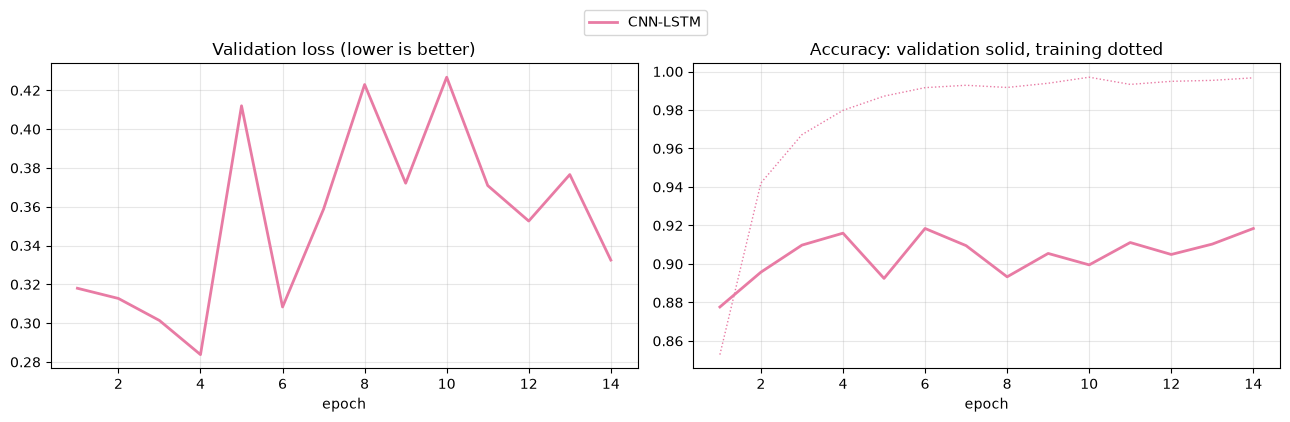

In [84]:
# ---------------------------------------------------------------------------------------------
# Training curves
#
# What it does:
#     Plot how each model learned over the epochs, using the history of its chosen seed.
#     Left: validation loss. Right: validation accuracy (solid) and training accuracy (dotted).
#
# Steps:
#     1. Give every model one fixed colour, reused in all later charts.
#     2. Make two side-by-side charts.
#     3. For each model: draw validation loss (left), validation and training accuracy (right).
#     4. Add titles, axis labels, grid and one shared legend.
#
# Reading it: a large gap between a model's solid and dotted lines means memorising (overfitting).
# ---------------------------------------------------------------------------------------------

COLOURS = { "LSTM": "#eb6834",                               # 1. one fixed colour per model,
           "CNN": "#1baf7a",                                 #    used in every chart below
           "CNN-LSTM": "#e87ba4"}


fig, ax = plt.subplots(1, 2, figsize=(13, 4))                # 2. left: loss, right: accuracy
for name, history in histories.items():                      # 3. one set of lines per model
    epochs = range(1, len(history["val_acc"]) + 1)      # runs can stop early
    ax[0].plot(epochs, history["val_loss"], color=COLOURS[name], linewidth=2, label=name)        # validation loss
    ax[1].plot(epochs, history["val_acc"], color=COLOURS[name], linewidth=2, label=name)         # validation accuracy (solid)
    ax[1].plot(epochs, history["train_acc"], color=COLOURS[name], linewidth=1, linestyle=":")    # training accuracy (dotted)
ax[0].set_title("Validation loss (lower is better)")         # 4. chart titles
ax[1].set_title("Accuracy: validation solid, training dotted")


for a in ax:                                                 #    same label and grid on both charts
    a.set_xlabel("epoch")
    a.grid(alpha=0.3)
handles, labels = ax[0].get_legend_handles_labels()          #    model names for the legend
fig.legend(handles, labels, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.06))   # one shared legend
plt.tight_layout()                                           # fit both charts without overlap
plt.show()

## Step 6: test the models

Load each model's best saved version and run it once on the test data, which none of them has seen.

- **Accuracy:** the share of windows a model got right.
- **Macro F1:** the average score across all gestures, each counted equally. It drops if any one gesture is often missed.
- **Model time:** how long one window takes on this computer, one window at a time, as in live use.
- **Total delay:** window length plus model time. The target is under 300 ms.

In [85]:
def predict(model, loader):
    """
    What it does:
        Predict the gesture for every window in a loader. Return the class numbers.

    Steps:
        1. Switch to evaluation mode and turn off gradient tracking.
        2. For each batch: move it to the model's device, compute scores, keep the highest-scoring gesture.
        3. Join all batches into one array.
    """
    model.eval()                                             # 1. dropout off, batch norm fixed
    predictions = []                                         #    one array of predictions per batch
    with torch.no_grad():                                    #    no gradients: faster, weights unchanged
        for windows, _ in loader:                            # 2. labels not needed here
            predictions.append(model(windows.to(DEVICE)).argmax(dim=1).cpu().numpy())   # back to CPU for numpy
    return np.concatenate(predictions)                       # 3. all batches as one array, in loader order



def time_one_window_ms(model):
    """
    What it does:
        Measure the average time (ms) to classify one window, as in live use.

    Steps:
        1. Take one test window and move it to the model's device.
        2. Run the model 20 times without timing (warm-up).
        3. Time 200 runs and return the average in milliseconds.
    """
    one_window = torch.tensor(X_test[:1]).to(DEVICE)         # 1. a single window: [1, time, 8]
    model.eval()                                             #    same mode as live use
    with torch.no_grad():                                    #    no gradients, as in live use
        for _ in range(20):                        # warm-up runs
            model(one_window)
        start = time.perf_counter()                          # 3. precise timer
        for _ in range(200):                                 #    many runs smooth out timing noise
            model(one_window)
    return (time.perf_counter() - start) / 200 * 1000        #    average per run, seconds -> ms

In [86]:
# ---------------------------------------------------------------------------------------------
# Test every model once
#
# What it does:
#     Load each seed's best saved weights, run them once on the unseen test data, and collect one
#     row of results per model: accuracy and macro F1 (mean over seeds), size, speed and delay.
#
# Steps:
#     1. For each model and each seed: load the best weights and predict the test windows.
#     2. Score accuracy and macro F1 for that seed.
#     3. Keep the chosen seed's model and predictions for the later charts and saving.
#     4. Time one window with the chosen model.
#     5. Store the averages over seeds plus size, speed, delay and training time.
# ---------------------------------------------------------------------------------------------

models = {}                                                  # chosen trained model per name
test_predictions = {}                                        # chosen model's test predictions per name
results = []                                                 # one dict per model -> results table


for name in MODEL_CLASSES:
    accs, f1s = [], []                                       # scores of each seed
    for seed in SEEDS:
        model = build_model(name)                            # 1. empty model of the right shape
        model.load_state_dict(torch.load(f"best_{name}_seed{seed}.pt", map_location=DEVICE))   # best weights, loaded onto the device in use
        preds = predict(model, test_loader)                  #    predicted gesture per test window
        accs.append(accuracy_score(y_test, preds))           # 2. share of windows correct
        f1s.append(f1_score(y_test, preds, average="macro")) #    average F1 over gestures, each counted equally
        if seed == chosen_seed[name]:           # keep one model per type for the later plots and saving
            models[name] = model
            test_predictions[name] = preds



    model_ms = time_one_window_ms(models[name])              # 4. ms per window, as in live use
    results.append({                                         # 5. one row of the results table
        "model": name,
        "accuracy": np.mean(accs),                           # mean over seeds
        "accuracy std": np.std(accs),                        # spread over seeds
        "macro F1": np.mean(f1s),                            # mean over seeds
        "parameters": sum(p.numel() for p in models[name].parameters()),   # model size
        "model time (ms)": model_ms,
        "total delay (ms)": WINDOW_MS + model_ms,            # window length + model time
        "training time (s)": training_seconds[name]})        # average per seed

### Compare with a simple baseline

What each column means

- Accuracy: the share of test windows classified correctly. CNN-LSTM got 95.3% right.
- Macro F1: a score from 0 to 1 that counts all 7 gestures equally. If one gesture is often missed, this drops even when overall accuracy looks fine. When it’s close to accuracy, as it is here, no single gesture is being badly neglected.
- Parameters: how many numbers the model learns, which is a rough measure of its size.
- Model time (ms): how long the model takes to classify one window on your computer. All five are under about 2 ms, which is negligible.
- Total delay (ms): window length plus model time, so roughly 1,000 ms for every model.
training time (s): how long training took. All are under a minute.



In [87]:
def ablation_check(X_train, y_train, X_test, y_test, results_table, model_names):
    """
    What it does:
        Test how much accuracy comes from simple activity strength versus the deep models.
        Train LDA on reduced versions of each window and compare with the best deep model.

    Steps:
        1. Reduce every window to 8 numbers: per-channel RMS (strength, order thrown away).
        2. Reduce every window to 8 numbers: the single middle sample (one snapshot).
        3. Train LDA on each reduced training set; score it on the reduced test set.
        4. Add the existing LDA baseline (32 hand-made features) and the best deep model.
        5. Print and return all four results, lowest to highest.
    """
    reductions = {
        "LDA: one sample per window (8 numbers)":   lambda W: W[:, W.shape[1] // 2, :],             # 2. middle sample   [windows, 8]
        "LDA: per-channel RMS (8 numbers)":          lambda W: np.sqrt(np.mean(W ** 2, axis=1)),    # 1. strength only   [windows, 8]
    }

    rows = []
    for label, reduce in reductions.items():                         # 1-3. reduced inputs
        lda = LinearDiscriminantAnalysis().fit(reduce(X_train), y_train)                         # 3. train on reduced training windows
        rows.append({"input": label, "accuracy": accuracy_score(y_test, lda.predict(reduce(X_test)))})   #    score on reduced test windows

    rows.append({"input": "LDA: 32 hand-made features",              # 4. existing results
                 "accuracy": results_table.loc["LDA baseline", "accuracy"]})
    best_name = results_table.loc[list(model_names), "accuracy"].idxmax()   #    best deep model by test accuracy
    rows.append({"input": f"Best deep model ({best_name})",
                 "accuracy": results_table.loc[best_name, "accuracy"]})

    table = pd.DataFrame(rows).set_index("input").sort_values("accuracy")   # 5. lowest first
    for label, acc in table["accuracy"].items():                     #    one printed line per result
        print(f"{label:45s} {acc:6.1%}")
    return table

def hand_made_features(windows):
    """
    What it does:
        Compute 4 classic sEMG features per channel for every window (numpy version, input to the
        LDA baseline).

    Steps:
        1. RMS: square, average over time, square root (signal strength).
        2. MAV: average absolute value (average size).
        3. WL: sum of absolute changes between neighbouring samples (how much it wiggles).
        4. ZC: number of sign changes (zero crossings).
        5. Join into 32 numbers per window (8 channels x 4 features).
    """
    rms = np.sqrt(np.mean(windows ** 2, axis=1))                     # 1. signal strength       [windows, 8]
    mav = np.mean(np.abs(windows), axis=1)                           # 2. average size          [windows, 8]
    wl = np.sum(np.abs(np.diff(windows, axis=1)), axis=1)            # 3. how much it wiggles   [windows, 8]
    zc = np.sum(np.diff(np.sign(windows), axis=1) != 0, axis=1)      # 4. zero crossings        [windows, 8]
    return np.concatenate([rms, mav, wl, zc], axis=1)                # 5. side by side          [windows, 32]


The sequence models only earn their place if they beat a classifier that cannot see time at
all. This fits an LDA to the per-channel RMS of each window — eight numbers, every trace of
temporal structure discarded — and to a single sample per window.

If the RMS score lands close to your best deep model, the task is being solved by "how hard
is each electrode reading", not by how the signal evolves, and the recurrent layers are
decoration. That is the expected result when every gesture is one long steady hold: there
are no onsets or transitions in the data for a sequence model to work with.

In [88]:
# ---------------------------------------------------------------------------------------------
# LDA baseline, results table and ablation
#
# What it does:
#     Train LDA on the 32 hand-made features, add its scores to the results, run the ablation
#     check, and show both tables.
#
# Steps:
#     1. Train LDA on the training features; predict the test windows.
#     2. Turn the collected results into a table, one row per model, plus the LDA row.
#     3. Run the ablation check (RMS only, one sample only).
#     4. Display the results table and the ablation table.
# ---------------------------------------------------------------------------------------------

lda = LinearDiscriminantAnalysis()                                   # 1. simple linear classifier
lda.fit(hand_made_features(X_train), y_train)                        #    learn from training features only
lda_predictions = lda.predict(hand_made_features(X_test))            #    predicted gesture per test window

results_table = pd.DataFrame(results).set_index("model")             # 2. one row per model
results_table.loc["LDA baseline", "accuracy"] = accuracy_score(y_test, lda_predictions)                 #    LDA accuracy
results_table.loc["LDA baseline", "macro F1"] = f1_score(y_test, lda_predictions, average="macro")      #    LDA macro F1
ablation = ablation_check(X_train, y_train, X_test, y_test, results_table, MODEL_CLASSES)              # 3. ablation results

display(results_table.style.format({                                 # 4. formatted results table
    "accuracy": "{:.1%}",                                            #    e.g. 81.0%
    "accuracy std": "{:.1%}",
    "macro F1": "{:.3f}",                                            #    e.g. 0.783
    "parameters": "{:,.0f}",                                         #    e.g. 45,543
    "model time (ms)": "{:.2f}",
    "total delay (ms)": "{:.0f}",
    "training time (s)": "{:.0f}",
}, na_rep="-"))                                                      #    "-" where a value does not apply


display(ablation.style.format("{:.1%}"))                             #    ablation table as percentages

LDA: one sample per window (8 numbers)         21.8%
LDA: per-channel RMS (8 numbers)               70.4%
LDA: 32 hand-made features                     70.6%
Best deep model (CNN-LSTM)                     92.0%


,accuracy,accuracy std,macro F1,parameters,model time (ms),total delay (ms),training time (s)
model,,,,,,,
CNN-LSTM,92.0%,0.8%,0.906,"103,271",1.54,252,66
LDA baseline,70.6%,-,0.702,-,-,-,-


,accuracy
input,
LDA: one sample per window (8 numbers),21.8%
LDA: per-channel RMS (8 numbers),70.4%
LDA: 32 hand-made features,70.6%
Best deep model (CNN-LSTM),92.0%


### Results overview: `result_illustration`

Draws every test result in one call. Uses test predictions only; nothing is retrained.

| Output | Shows | Look for |
|---|---|---|
| Bar charts | test accuracy (dashed line = LDA baseline), parameters, model time per window | accuracy gained vs size and speed cost |
| Confusion matrices | true gesture (rows) vs predicted (columns), one per model + LDA | off-diagonal cells = gestures mixed up |
| Accuracy per recording | line chart + colour table, one recording per gesture | a recording every model fails → likely a data problem, not the model |
| Classification report | precision, recall, F1 per gesture for the best model | weak gestures (low recall / F1) |

**Returns:** `per_file` (accuracy per recording) and `best_name` (highest test accuracy).

In [89]:
def result_illustration(results_table, test_predictions, lda_predictions, y_test, test_file,
                        gesture_names, colours, split_by="chrono"):
    """
    What it does:
        Show all test results: summary bar charts, confusion matrices, accuracy per recording,
        and a per-gesture report for the best model.

    Steps:
        1. Bar charts: test accuracy (with LDA baseline line), parameters, model time.
        2. Confusion matrix for every model, plus the LDA baseline.
        3. Accuracy per recording: line chart and colour-coded table.
        4. Precision, recall and F1 per gesture for the best model.
        5. Return the per-recording table and the best model's name.
    """
    names = list(test_predictions)                                   # models, in training order

    # 1. Summary bar charts
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))                  # three charts in one row
    panels = [("accuracy", "Test accuracy"),                         # (results column, chart title)
              ("parameters", "Parameters (model size)"),
              ("model time (ms)", "Model time per window (ms)")]
    for a, (column, title) in zip(ax, panels):                       # same bar chart for each column
        a.bar(names, results_table.loc[names, column], color="#2a78d6", width=0.6)
        a.set_title(title)
        a.tick_params(axis="x", rotation=20)                         # tilted names
        a.grid(axis="y", alpha=0.3)                                  # light horizontal grid
        a.set_axisbelow(True)                                        # grid behind the bars
    ax[0].axhline(results_table.loc["LDA baseline", "accuracy"], color="grey",
                  linestyle="--", label="LDA baseline")              # baseline to beat
    ax[0].set_ylim(0, 1)                                             # 0-100% scale
    ax[0].legend(loc="lower right")
    for i, value in enumerate(results_table.loc[names, "accuracy"]): # value label above each bar
        ax[0].text(i, value + 0.02, f"{value:.1%}", ha="center")
    plt.tight_layout()
    plt.show()

    # 2. Confusion matrices (models in blue, LDA in grey)
    all_predictions = {**test_predictions, "LDA baseline": lda_predictions}        # models + LDA
    fig, axes = plt.subplots(1, len(all_predictions), figsize=(5.3 * len(all_predictions), 5))   # one matrix each
    for a, (name, preds) in zip(axes, all_predictions.items()):
        ConfusionMatrixDisplay.from_predictions(
            y_test, preds, display_labels=gesture_names, xticks_rotation=45, colorbar=False, ax=a,
            cmap="Greys" if name == "LDA baseline" else "Blues")    # rows = true, columns = predicted
        a.set_title(f"{name}: {results_table.loc[name, 'accuracy']:.1%}")
    plt.suptitle(f"Confusion matrices (test, split = {split_by})")
    plt.tight_layout()
    plt.show()

    # 3. Accuracy per recording (each file holds one gesture)
    per_file = pd.DataFrame({"recording": test_file, "gesture": np.array(gesture_names)[y_test]})   # one row per test window
    for name in names:
        per_file[name] = test_predictions[name] == y_test            # True = correct
    per_file = per_file.groupby(["recording", "gesture"]).mean()     # share correct per recording
    labels = [f"{rec} {gesture}" for rec, gesture in per_file.index]   # e.g. "04 radial"

    plt.figure(figsize=(13, 4))
    for name in names:                                               # one line per model
        plt.plot(labels, per_file[name], marker="o", markersize=6, linewidth=1.5,
                 color=colours.get(name), label=name)                # default colour if not in COLOURS
    plt.ylim(0, 1.02)
    plt.ylabel("test accuracy")
    plt.xlabel("recording (one gesture each)")
    plt.title("Test accuracy per recording")
    plt.grid(alpha=0.3)
    plt.legend(ncol=5, loc="lower left")
    plt.tight_layout()
    plt.show()
    display(per_file.style.format("{:.1%}").background_gradient(cmap="Blues", vmin=0.3, vmax=1.0))   # table, darker = higher

    # 4. Per-gesture report for the best model
    best_name = results_table.loc[names, "accuracy"].idxmax()        # highest test accuracy
    print(f"Best model on the test set: {best_name}\n")
    print(classification_report(y_test, test_predictions[best_name],
                                target_names=gesture_names, digits=3))   # precision, recall, F1 per gesture

    return per_file, best_name                                       # 5. for later cells

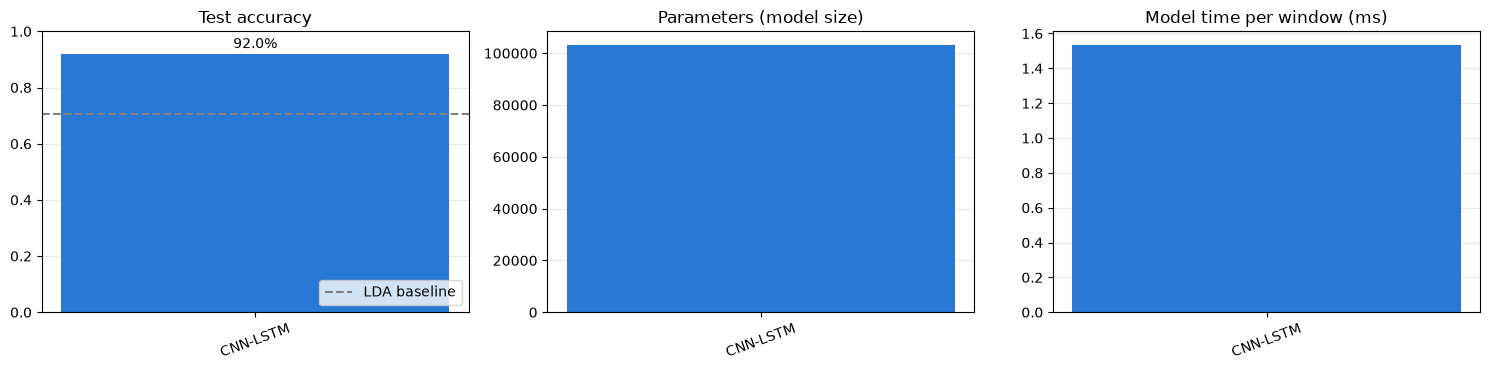

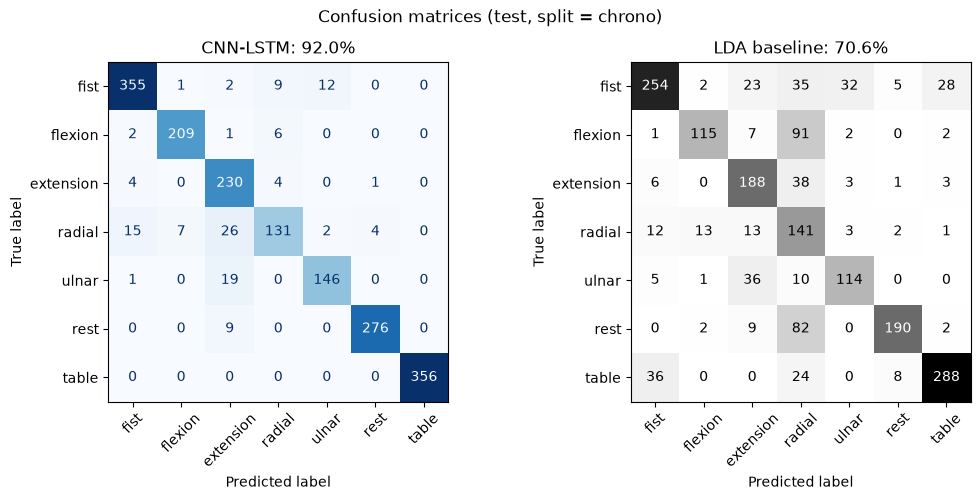

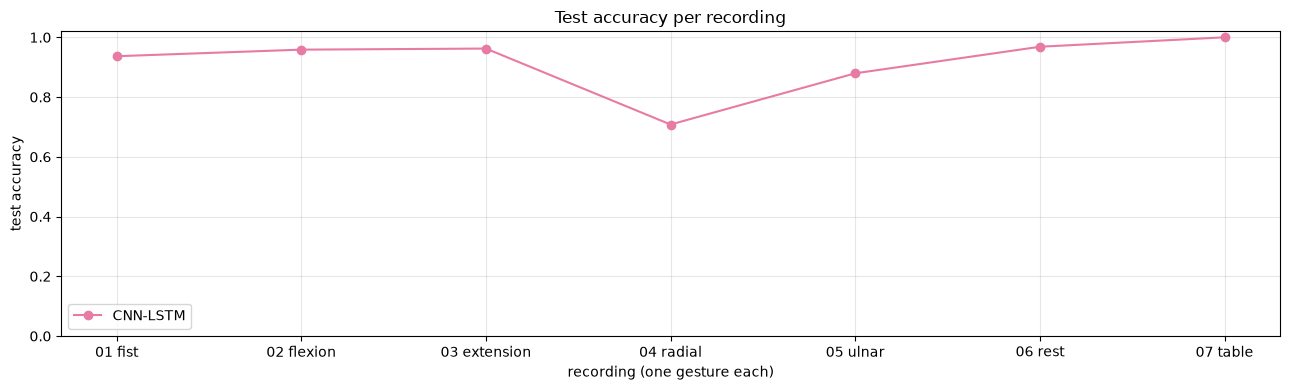

,,CNN-LSTM
recording,gesture,
01,fist,93.7%
02,flexion,95.9%
03,extension,96.2%
04,radial,70.8%
05,ulnar,88.0%
06,rest,96.8%
07,table,100.0%


Best model on the test set: CNN-LSTM

              precision    recall  f1-score   support

        fist      0.942     0.937     0.939       379
     flexion      0.963     0.959     0.961       218
   extension      0.801     0.962     0.875       239
      radial      0.873     0.708     0.782       185
       ulnar      0.912     0.880     0.896       166
        rest      0.982     0.968     0.975       285
       table      1.000     1.000     1.000       356

    accuracy                          0.932      1828
   macro avg      0.925     0.916     0.918      1828
weighted avg      0.934     0.932     0.931      1828



In [90]:
# Draw every test result and get the best model's name (used by the save step).
per_file, best_name = result_illustration(results_table, test_predictions, lda_predictions,
                                          y_test, test_file, GESTURE_NAMES, COLOURS, SPLIT_BY)   # charts, tables, report

## Step 7: save everything needed to use the model later

The weights alone are not enough. Live data must go through exactly the same filters, window size and normalisation, so those settings are saved in the same file as each model, for example `CNN-LSTM_semg.pt`.

The next cell also exports the model for the live program: a TorchScript file (`CNN-LSTM_ts.pt`, runs without the class code; checked to give the same scores) and `scaler.pkl` (channel mean, std and filter settings).

In [96]:
import pickle                                                # whole-object save (.pkl)
def save_model(name, model, channel_mean, channel_std, results_table):
    """
    What it does:
        Save a full checkpoint: the weights plus everything needed to rebuild the model and to
        prepare live windows exactly as in training. File: "{name}_semg.pt".

    Steps:
        1. Collect the weights, normalisation, preprocessing settings, window and gesture details,
           test scores and model settings in one dictionary.
        2. Save it with torch.save.
    """
    torch.save({ # rebuild with build_model(name, params=...)
        "model_name": name,                                  # which class to rebuild
        "model_weights": model.state_dict(),                 # trained weights
        "channel_mean": channel_mean.tolist(),     # plain lists, so torch.load works without extra flags
        "channel_std": channel_std.tolist(),
        "preprocessing": PREP,                     # every pp.preprocess setting
        "window_size": WINDOW_SIZE,                          # samples per window
        "step": STEP,                                        # samples between windows
        "gestures": GESTURE_NAMES,                           # class number -> gesture name
        "split": SPLIT_BY,                                   # how the data was split
        "test_accuracy": float(results_table.loc[name, "accuracy"]),   # mean over seeds
        "test_macro_f1": float(results_table.loc[name, "macro F1"]),   # mean over seeds
        "params": PARAMS[name]}, f"{name}_semg.pt")          # model + training settings
    print(f"saved {name}_semg.pt")


with open(f"{best_name}_semg_model.pkl", "wb") as f:        # whole model object (needs the class code to load)
    pickle.dump(models[best_name], f)
save_model(best_name, models[best_name], channel_mean, channel_std, results_table)   # full checkpoint (.pt)
torch.save(models[best_name].state_dict(), f"{best_name}_model.pt")   # weights only

saved CNN-LSTM_semg.pt


In [97]:
# ---------------------------------------------------------------------------------------------
# Export for live use: TorchScript model + scaler
#
# What it does:
#     Save the best model as TorchScript (runs without the class code) and save the normalisation
#     in the format the live program reads.
#
# Steps:
#     1. Copy the best model to the CPU in evaluation mode.
#     2. Trace it with two test windows; check the traced model gives the same scores on 50 windows.
#     3. Save the traced model as "{name}_ts.pt".
#     4. Save channel mean, std and filter settings to "scaler.pkl".
# ---------------------------------------------------------------------------------------------

import copy, pickle

name = best_name
m = copy.deepcopy(models[name]).cpu().eval()          # 1. CPU copy, eval mode

with torch.no_grad():
    traced = torch.jit.trace(m, torch.tensor(X_test[:2]))   # 2. [batch, time, 8]
    x = torch.tensor(X_test[:50])                           #    check another batch size
    assert torch.allclose(traced(x), m(x), atol=1e-5)       #    same scores as the original
traced.save(f"{name}_ts.pt")                                # 3. file for live use

# scaler in the format Preprocessing.load_scaler expects
settings = {"fs": SAMPLE_RATE, "lowcut": PREP["low_hz"], "highcut": PREP["high_hz"], "notch": 0}   # 4. filter settings
with open("scaler.pkl", "wb") as f:
    pickle.dump({"mean": np.asarray(channel_mean),          #    per-channel mean (training data)
                 "std": np.asarray(channel_std),            #    per-channel std (training data)
                 "settings": settings}, f)

c:\Users\micha\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\jit\_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
c:\Users\micha\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\jit\_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Step 8: automated tuning with Optuna

In [92]:
%pip install optuna

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### How it works
Optuna tries many settings automatically. Each **trial** trains the model once (seed 0) with one set of
settings and is scored by its **best validation accuracy**. The test set is not used.

```
for each model in MODEL_CLASSES:
    open (or resume) a study in tuning.db
    trial 0 = current PARAMS                      # baseline, scored the same way
    repeat until N_TRIALS:
        settings = suggest_params(trial, model)   # Optuna picks the values
        train with settings; report val accuracy every epoch
        stop early if below the median of earlier trials (pruner) or no gain for PATIENCE epochs
        score = best val accuracy
    best_params[model] = settings of the best trial
```

- **TPE sampler:** the first ~10 trials explore; later trials try settings close to the best so far.
- **Median pruner:** from trial 10 and epoch 5, a trial below the median of earlier trials is stopped.

### Search space (CNN-LSTM)
| Setting | Range |
|---|---|
| `lr` | 0.0001–0.01 (log) |
| `weight_decay` | 0.000001–0.01 (log) |
| `batch_size` | 32, 64, 128 |
| `dropout` | 0.0–0.5 |
| `width` | 16, 32, 64, 128 |
| `kernel_size` | 3, 5, 7 |
| `hidden` | 32, 64, 128, 256 |
| `cnn_layers` | 1–4 (skipped if the reach is over 2 × `WINDOW_SIZE`) |
| `stride` | 1, 2 |
| `lstm_layers` | 1–3 |
| `use_features` | False, True |

100 trials. Pruned trials count towards the total.

### Saving and resuming
- Every trial is saved in `tuning.db`; re-running the cell continues where it stopped.
- **Delete `tuning.db` when the data changes.**
- `results_before_tuning.csv` keeps the results from before tuning.

### Next
Run the last cell (`PARAMS = best_params`), then re-run Steps 5–7 (3 seeds, test once).

In [93]:
# ---------------------------------------------------------------------------------------------
# Step 8: automated tuning with Optuna
#
# What it does:
#     Search the model's settings automatically. Every trial trains one model (seed 0) with
#     suggested settings and is scored by its best validation accuracy. The test set is not used.
#
# Steps:
#     1. N_TRIALS: number of trials per model.
#     2. suggest_params: which settings each model may change, and their ranges.
#     3. For each model: create (or resume) a study saved in tuning.db.
#     4. Trial 0 = the current PARAMS, so the baseline is scored the same way.
#     5. Run the remaining trials; weak trials are stopped early by the pruner.
#     6. Store and print the best settings per model.
# ---------------------------------------------------------------------------------------------

import json                                                  # save the best settings
import optuna                                                # tuning library

N_TRIALS = {"CNN-LSTM": 100,                                 # 1. trials per model
            "CNN": 50,
            "LSTM": 50}


# Ranges of the settings to tune.
# p holds the settings shared by all models; model-specific settings are added below.
def suggest_params(trial, name):
    """
    What it does:
        Ask Optuna for one value of every tunable setting of the given model. Return the settings.

    Steps:
        1. Shared training settings: learning rate, weight decay, batch size, dropout.
        2. LSTM only: memory size and number of layers.
        3. CNN and CNN-LSTM: filter count and filter size.
        4. CNN-LSTM only: memory size, conv layers (skip if the reach is over 2 x WINDOW_SIZE),
           stride, LSTM layers, hand-made features on/off.
        5. CNN only: number of layers; skip layouts whose reach does not fit the window.
    """
    p = {"lr":           trial.suggest_float("lr", 1e-4, 1e-2, log=True),            # 1. log scale: 0.0001 .. 0.01
         "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
         "batch_size":   trial.suggest_categorical("batch_size", [32, 64, 128]),
         "dropout":      trial.suggest_float("dropout", 0.0, 0.5)
        }

    if name in ("LSTM"):                                                               # 2.
        p["hidden"] = trial.suggest_categorical("hidden", [32, 64, 128, 256])
        p["layers"] = trial.suggest_int("layers", 1, 3)

    if name in ("CNN", "CNN-LSTM"):                                                    # 3.
        p["width"] = trial.suggest_categorical("width", [16, 32, 64, 128])    #up to 256 as width * 2
        p["kernel_size"] = trial.suggest_categorical("kernel_size", [3, 5, 7])

    if name == "CNN-LSTM":                                                             # 4.
        p["hidden"] = trial.suggest_categorical("hidden", [32, 64, 128, 256])
        p["cnn_layers"] = trial.suggest_int("cnn_layers", 1, 4)
        reach = 1 + (p["kernel_size"] - 1) * p["cnn_layers"]   # samples the CNN can see
        if reach > 2 * WINDOW_SIZE:
            raise optuna.TrialPruned()                         # mostly padding: skip
        p["stride"] = trial.suggest_categorical("stride", [1, 2])
        p["lstm_layers"] = trial.suggest_int("lstm_layers", 1, 3)
        p["use_features"] = trial.suggest_categorical("use_features", [False, True])

    if name == "CNN":                                                                  # 5.
        p["width"] = trial.suggest_categorical("width", [16, 32, 64, 128])
        p["kernel_size"] = trial.suggest_categorical("kernel_size", [3, 5, 7])
        p["n_layers"] = trial.suggest_int("n_layers", 2, 4)
        reach = 1 + (p["kernel_size"] - 1) * p["n_layers"]       # samples the CNN can see
        if reach < WINDOW_SIZE or reach > 2 * WINDOW_SIZE:
            raise optuna.TrialPruned()                         # must cover the window, not much more
    return p


# Run the tuning for each model, saving the best parameters and validation accuracy
optuna.logging.set_verbosity(optuna.logging.WARNING)         # warnings only, no line per trial
results_table.to_csv("results_before_tuning.csv")            # keep the results from before tuning
best_params = {}                                             # best settings per model




# run trials for each model, using the objective function to train and evaluate the model with the suggested parameters
for name in MODEL_CLASSES:

    # objective function for the tuning, which trains the model and returns the best validation accuracy
    def objective(trial):
        history = train_model(name, seed=0, params=suggest_params(trial, name), trial=trial)   # one trial = one training run
        return max(history["val_acc"])                       # trial score


    study = optuna.create_study(direction="maximize",                           # 3. higher score is better
                                study_name=f"{name}_{WINDOW_MS}ms_{SAMPLE_RATE}Hz",     # label for the search in the save file
                                storage="sqlite:///tuning.db",                          # database file that keeps every trial
                                load_if_exists=True,                                    # can stop and resume
                                sampler=optuna.samplers.TPESampler(seed=0),             # method of choosing each trial's settings
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=5))   # early stop of weak trials


    if len(study.trials) == 0:                               # 4. new study only
        study.enqueue_trial(PARAMS[name])                    #    trial 0 = the current settings
    done = sum(t.state.is_finished() for t in study.trials)  #    trials already finished (when resuming)
    study.optimize(objective, n_trials=max(0, N_TRIALS[name] - done), show_progress_bar=True)   # 5. run the rest



    best_params[name] = study.best_params                    # 6. best settings found
    print(f"{name}: best validation accuracy {study.best_value:.1%}  {study.best_params}")

  0%|          | 0/96 [00:14<?, ?it/s]

[W 2026-10-27 11:02:26,524] Trial 4 failed with parameters: {'lr': 0.0012520653814999472, 'weight_decay': 0.0007257005721594283, 'batch_size': 32, 'dropout': 0.32294705653332806, 'width': 64, 'kernel_size': 3, 'hidden': 32, 'cnn_layers': 4, 'stride': 2, 'lstm_layers': 3, 'use_features': False} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "c:\Users\micha\AppData\Local\Programs\Python\Python312\Lib\site-packages\optuna\study\_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "C:\Users\micha\AppData\Local\Temp\ipykernel_21508\3634647406.py", line 60, in objective
    history = train_model(name, seed=0, params=suggest_params(trial, name), trial=trial)
              ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\micha\AppData\Local\Temp\ipykernel_21508\3459779510.py", line 97, in train_model
    train_loss, train_acc = train_one_epoch(

KeyboardInterrupt: 

In [ ]:
# ---------------------------------------------------------------------------------------------
# Use the tuned settings
#
# What it does:
#     Replace PARAMS with the best settings found by the search and save them to a file.
#     Then re-run the training loop (Step 5) to Step 7 for the tuned results.
# ---------------------------------------------------------------------------------------------

PARAMS = best_params                                                 # tuned settings for every model
json.dump(PARAMS, open("best_params.json", "w"), indent=1)           # keep a copy on disk
print("Now re-run Step 5 (the training loop) to Step 7 to train the tuned models with every seed and test once.")